# 01_target_definition
1. 데이터 로드
2. 고객별 최대 구매 간격 계산 
   - 고객 별로 '재구매하는 데 걸린 시간'을 전부 측정
3. 이탈 기준일(Cut-off) 도출
   - 통계치(75분위수)를 확인해보니 203일 도출
   - 데이터 종료일에서 203일을 뺀 '2020-03-03'을 Cut-off Date로 확정
4. 라벨(Churn) 생성
   - Cut-off 이전 가입 유저 중 '30일 이상 활동한 유저'만 필터링
   - Cut-off 이후(미래 203일)에 구매 기록이 없으면 churn=1(이탈) 부여 => 결과물 : df_label (customer_id, churn)
5. 파생 feature 생성
   - 오직 Cut-off 이전 과거 데이터만 사용 => 결과물 : 각 피쳐가 담긴 데이터프레임
   - 5-1. 기본 RFM : 총 구매 횟수(frequency), 구매 금액 합계/평균/최대값
   - 5-2. Recency : Cut-off 일자 기준으로 마지막 구매일이 며칠 전인가?
   - 5-3. 활동성 : 최근 90일 / 180일 동안 각각 몇 번 구매했는가?
   - 5-4. 구매간격 : 유저별 평균 구매 주기 및 주기 편차(std)
   - 5-5. 다양성 : 얼마나 다양한 상품과 카테고리를 샀는가?
   - 5-6. 취향 : 가장 자주 산 카테고리/인덱스 그룹(패션 스타일)이 무엇인가? 

6. 데이터 결합 (Merge)
   - 라벨을 중심에 두고, 각 파생변수들과 고객 메타정보를 customer_id 기준으로 Left Join

7. 데이터 누수 검증
   - 중복 데이터 확인
   - 데이터 누수 확인
   - "유지 고객(0)이 이탈 고객(1)보다 과거 구매 횟수가 많다" 검증

8. 데이터 저장

## 1. 데이터 로드

In [1]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
trans = pd.read_csv('./raw/transactions_train.csv', nrows=100000)
customers = pd.read_csv('./raw/customers.csv')
articles = pd.read_csv('./raw/articles.csv')

print(f"Transactions 데이터 크기: {trans.shape}")
print(f"고객 데이터 크기: {customers.shape}")
print(f"상품 데이터 크기: {articles.shape}")

Transactions 데이터 크기: (100000, 5)
고객 데이터 크기: (1371980, 7)
상품 데이터 크기: (105542, 25)


In [3]:
trans.head()

,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.016932,2


In [4]:
customers.head()

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


In [5]:
articles.head()

,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [6]:
trans.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   t_dat             100000 non-null  str    
 1   customer_id       100000 non-null  str    
 2   article_id        100000 non-null  int64  
 3   price             100000 non-null  float64
 4   sales_channel_id  100000 non-null  int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 3.8 MB


In [7]:
customers.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 1371980 entries, 0 to 1371979
Data columns (total 7 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   customer_id             1371980 non-null  str    
 1   FN                      476930 non-null   float64
 2   Active                  464404 non-null   float64
 3   club_member_status      1365918 non-null  str    
 4   fashion_news_frequency  1355969 non-null  str    
 5   age                     1356119 non-null  float64
 6   postal_code             1371980 non-null  str    
dtypes: float64(3), str(4)
memory usage: 73.3 MB


In [8]:
articles.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 105542 entries, 0 to 105541
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   article_id                    105542 non-null  int64
 1   product_code                  105542 non-null  int64
 2   prod_name                     105542 non-null  str  
 3   product_type_no               105542 non-null  int64
 4   product_type_name             105542 non-null  str  
 5   product_group_name            105542 non-null  str  
 6   graphical_appearance_no       105542 non-null  int64
 7   graphical_appearance_name     105542 non-null  str  
 8   colour_group_code             105542 non-null  int64
 9   colour_group_name             105542 non-null  str  
 10  perceived_colour_value_id     105542 non-null  int64
 11  perceived_colour_value_name   105542 non-null  str  
 12  perceived_colour_master_id    105542 non-null  int64
 13  perceived_colour_master_n

## 2. 고객별 최대 구매 간격 계산

In [9]:
# 전체 거래 데이터 로드 및 유저별 최대 구매 간격 계산
trans_all = pd.read_csv('./raw/transactions_train.csv', usecols=['t_dat', 'customer_id'])
trans_all['t_dat'] = pd.to_datetime(trans_all['t_dat'])

# 유저별 구매 간격 계산
trans_sorted = trans_all.sort_values(['customer_id', 't_dat'])
trans_sorted['diff'] = trans_sorted.groupby('customer_id')['t_dat'].diff().dt.days
user_max_diff = trans_sorted.groupby('customer_id')['diff'].max().dropna()

## 3. cut_off 기준일 확정
- 데이터에서 고객들의 평균적인 재구매 간격을 확인
- 구매 횟수가 1회인 고객은 직전 구매일이 없어서 diff값이 NaN

In [10]:
# 기초 통계량 확인
median_diff = user_max_diff.median()
mean_diff = user_max_diff.mean()
q75_days_calc = user_max_diff.quantile(0.75)

print("▶ 이탈 기준일 설정:")
print(f" - 중앙값(50%) : {median_diff}일")
print(f" - 평균값(Mean): {mean_diff:.1f}일")
print(f" - 75분위수(Q3): {q75_days_calc}일")

# 전후 구간 밀도 분석 함수 (꺾임점 증명용)
def analyze_window_density(data, standard_days, window=30):
    before_count = ((data >= standard_days - window) & (data < standard_days)).sum() # 기준일 전 후 30일 구간 최대 구매 공백기 계산
    after_count = ((data >= standard_days) & (data < standard_days + window)).sum()
    total = len(data)
    before_pct = (before_count / total) * 100
    after_pct = (after_count / total) * 100
    drop_rate = ((before_pct - after_pct) / before_pct) * 100 if before_pct > 0 else 0 # 급감률 계산
    print(f" 기준일 [{int(standard_days)}일] 전후 {window}일 밀도 급감률: {drop_rate:.1f}%")

print("▶ 주요 후보 날짜별 데이터 감속 비율 비교:")
analyze_window_density(user_max_diff, standard_days=median_diff)    # 중앙값 기준
analyze_window_density(user_max_diff, standard_days=mean_diff)      # 평균값 기준
analyze_window_density(user_max_diff, standard_days=q75_days_calc)  # 75분위수 기준

▶ 이탈 기준일 설정:
 - 중앙값(50%) : 112.0일
 - 평균값(Mean): 131.9일
 - 75분위수(Q3): 203.0일
▶ 주요 후보 날짜별 데이터 감속 비율 비교:
 기준일 [112일] 전후 30일 밀도 급감률: -7.4%
 기준일 [131일] 전후 30일 밀도 급감률: 3.8%
 기준일 [203일] 전후 30일 밀도 급감률: 21.3%


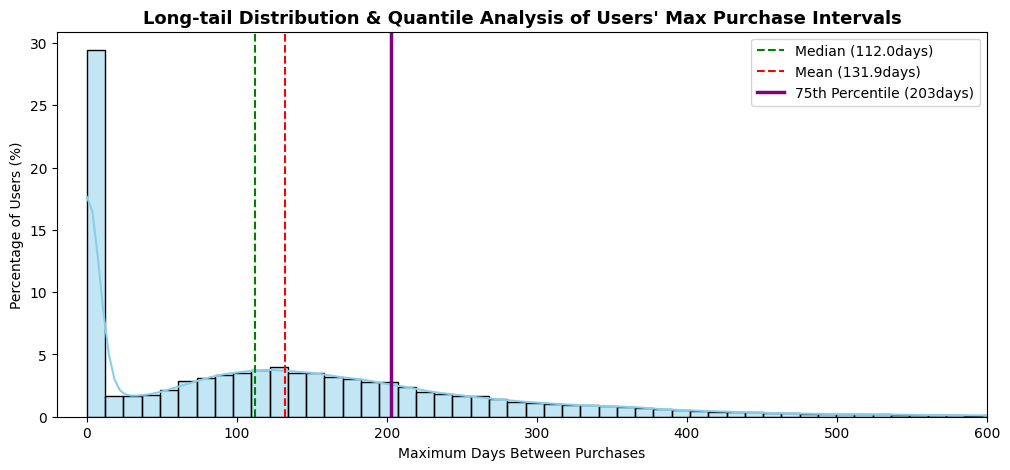

In [11]:
# long-tail distribution
plt.figure(figsize=(12, 5))
sns.histplot(user_max_diff, bins=60, kde=True, color='skyblue', stat='percent')
plt.axvline(median_diff, color='green', linestyle='--', label=f'Median ({median_diff}days)')
plt.axvline(mean_diff, color='red', linestyle='--', label=f'Mean ({mean_diff:.1f}days)')
plt.axvline(q75_days_calc, color='purple', linestyle='-', linewidth=2.5, label=f'75th Percentile ({int(q75_days_calc)}days)')
plt.title("Long-tail Distribution & Quantile Analysis of Users' Max Purchase Intervals", fontsize=13, fontweight='bold')
plt.xlabel("Maximum Days Between Purchases")
plt.ylabel("Percentage of Users (%)")
plt.xlim(-20, 600)
plt.legend()
plt.show()

In [12]:
# 검증한 통계치를 기반으로 '75분위수'를 최종 이탈 기준일로 확정
q75_days = int(q75_days_calc)

# 데이터 시작일, 종료일 및 cut_off_date 계산
min_date = trans_all['t_dat'].min()
max_date = trans_all['t_dat'].max()
cut_off_date = max_date - pd.Timedelta(days=q75_days)

print("[전체 거래 데이터 기간 확인]")
print(f"-   최종 이탈 기준일  : {q75_days}일 (Q3)")
print(f"-   데이터 시작일 (Min Date) : {min_date.date()}")
print(f"-   데이터 종료일 (Max Date)    : {max_date.date()}")
print(f"-   cut_off 기준일    : {cut_off_date.date()}")
print(f"-   전체 데이터 수집 기간   : {(max_date - min_date).days + 1}일")

print("[최종 시간 축 구조]")
print(f"    - 데이터 시작일부터 cut_off_date까지 : {trans_all['t_dat'].min().date()} ~ {cut_off_date.date()} (약 {len(trans_all[trans_all['t_dat'] <= cut_off_date])}건)")
print(f"    - cut_off_date부터 데이터 종료일까지 : {cut_off_date.date()} ~ {max_date.date()} (약 {len(trans_all[trans_all['t_dat'] > cut_off_date])}건)")

[전체 거래 데이터 기간 확인]
-   최종 이탈 기준일  : 203일 (Q3)
-   데이터 시작일 (Min Date) : 2018-09-20
-   데이터 종료일 (Max Date)    : 2020-09-22
-   cut_off 기준일    : 2020-03-03
-   전체 데이터 수집 기간   : 734일
[최종 시간 축 구조]
    - 데이터 시작일부터 cut_off_date까지 : 2018-09-20 ~ 2020-03-03 (약 22991230건)
    - cut_off_date부터 데이터 종료일까지 : 2020-03-03 ~ 2020-09-22 (약 8797094건)


## 4. 라벨(Churn) 생성

- cut_off 이후에 구매했으면 → 유지 (0)
- cut_off 이후에 구매 안 했으면 → 이탈 (1)
- 가입 30일 미만 초기 유저는 제외 (판단 근거가 부족)
- 데이터 누수 방지를 위해 라벨 생성에 쓴 임시 컬럼(`recency_for_label`, `threshold`)은 바로 삭제

In [13]:
# 1. 시점 격리: 피처용 과거 데이터와 라벨용 미래 데이터로 명확히 분리
df_past_base = trans_all[trans_all['t_dat'] <= cut_off_date]
df_future_base = trans_all[trans_all['t_dat'] > cut_off_date]

# 고객의 첫 구매일과 가입기간(tenure) 계산 (cut_off 이전 데이터로만 계산)
user_stats = df_past_base.groupby('customer_id')['t_dat'].agg(['min', 'max']).reset_index()
user_stats.columns = ['customer_id', 'first_buy', 'last_buy_past']
user_stats['tenure'] = (cut_off_date - user_stats['first_buy']).dt.days

# 3. 30일 미만 초기 고객 제외 (30일 이상 활동 고객만 분석 대상으로 선정)
df_label = user_stats[user_stats['tenure'] >= 30].copy()

# 4. 라벨 생성

# 미래 구간(203일 동안)에 단 한 번이라도 구매한 이력이 있는 유니크한 고객 ID만 추출
active_users_in_future = df_future_base['customer_id'].unique()

# 미래에 구매 기록이 있다면 -> Churn = 0 (유지)
# 미래에 구매 기록이 없다면 -> Churn = 1 (이탈)
df_label['churn'] = df_label['customer_id'].isin(active_users_in_future).apply(lambda x: 0 if x else 1)

# customer_id와 churn만 남기고 정리
df_label = df_label[['customer_id', 'churn']]

print(f"1. 분석 대상 유저 수 (가입 30일 이상): {len(df_label):,}명")
print(f"\n2. churn 라벨 분포")
print(df_label['churn'].value_counts())
print(f"\n3. 이탈률: {df_label['churn'].mean() * 100:.2f}%")

1. 분석 대상 유저 수 (가입 30일 이상): 1,143,652명

2. churn 라벨 분포
churn
1    572053
0    571599
Name: count, dtype: int64

3. 이탈률: 50.02%


## 5. 파생 feature 생성
- 모두 cut_off 이전 데이터만 사용
- 전체 거래 데이터를 로드하고, cut_off 이전으로 필터링한 뒤 모든 피처를 한번에 계산

In [14]:
# 피처 생성을 위해 전체 거래 데이터 로드
trans_feat = pd.read_csv('./raw/transactions_train.csv',
                         usecols=['t_dat', 'customer_id', 'article_id', 'price'])
trans_feat['t_dat'] = pd.to_datetime(trans_feat['t_dat'])

# cut_off 이전 데이터만 사용
trans_feat = trans_feat[trans_feat['t_dat'] <= cut_off_date].copy()
print(f"-   feature 생성 대상 거래 수: {len(trans_feat):,}건 (cut_off 이전)")

-   feature 생성 대상 거래 수: 22,991,230건 (cut_off 이전)


### 5-1. 기본 RFM 피처
- Recency (최근성): 고객이 얼마나 최근에 우리 가게에 왔는가?
- Frequency (빈도): 얼마나 자주 샀는가?
- Monetary (금액): 돈을 얼마나 많이 썼는가?

In [15]:
user_rfm = trans_feat.groupby('customer_id').agg(
    frequency    = ('article_id', 'count'),   # 총 구매 횟수
    price_mean   = ('price', 'mean'),         # 평균 구매 금액
    price_sum    = ('price', 'sum'),          # 총 구매 금액
    price_max    = ('price', 'max'),          # 최고 구매 금액
).reset_index()

user_rfm.head()

,customer_id,frequency,price_mean,price_sum,price_max
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,15,0.033634,0.504508,0.054220
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,71,0.031518,2.237780,0.084729
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,7,0.030734,0.215136,0.050831
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,2,0.030492,0.060983,0.030492
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,6,0.035647,0.213881,0.059305


### 5-2. Recency 피처
- max_date - last_buy로 계산하면 정답 라벨과 100% 동일한 의미라 데이터 누수가 된다.
- (cut_off_date - last_buy)로 생성 : 관측 시점 기준 마지막 구매가 얼마나 오래되었나. (정답과 무관한 피처)

In [16]:
# cut_off 기준 마지막 구매일 = last_buy_before_cutoff
user_last_buy = trans_feat.groupby('customer_id')['t_dat'].max().reset_index()
user_last_buy.columns = ['customer_id', 'last_buy_before_cutoff']
user_last_buy['recency'] = (cut_off_date - user_last_buy['last_buy_before_cutoff']).dt.days
user_last_buy = user_last_buy.drop(columns=['last_buy_before_cutoff'])

user_last_buy.head()

,customer_id,recency
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,96
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,2
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,29
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,268
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,146


### 5-3. 활동성 : 최근 구매 활동 피처
- 최근 90일, 180일 동안 각각 몇 번 구매했는가?
- 고객이 이탈할 때는 방문이 갑자기 뚝 끊기기보다 방문 빈도가 점점 뜸해지는 전조증상을 보임
- 모델이 고객의 최근 활동성 변화를 반영할 수 있도록 파생변수 추가

In [17]:
# 최근 90일, 180일 기준일
date_90d  = cut_off_date - pd.Timedelta(days=90)
date_180d = cut_off_date - pd.Timedelta(days=180)

# 최근 90일 구매 횟수
freq_90d = (
    trans_feat[trans_feat['t_dat'] >= date_90d]
    .groupby('customer_id')['article_id'].count()
    .reset_index()
    .rename(columns={'article_id': 'frequency_last_90d'})
)

# 최근 180일 구매 횟수
freq_180d = (
    trans_feat[trans_feat['t_dat'] >= date_180d]
    .groupby('customer_id')['article_id'].count()
    .reset_index()
    .rename(columns={'article_id': 'frequency_last_180d'})
)

print(f"- 최근 90일 내 구매 기록 있는 고객: {len(freq_90d):,}명")
print(f"- 최근 180일 내 구매 기록 있는 고객: {len(freq_180d):,}명")

- 최근 90일 내 구매 기록 있는 고객: 485,365명
- 최근 180일 내 구매 기록 있는 고객: 704,745명


### 5-4. 구매 간격 피처
- 얼마나 규칙적으로 오는지. 고객별 평균 구매 주기 및 주기 편차(std)

In [18]:
# 유저별 구매 간격 계산
trans_sorted_feat = trans_feat.sort_values(['customer_id', 't_dat'])
trans_sorted_feat['interval'] = (
    trans_sorted_feat.groupby('customer_id')['t_dat'].diff().dt.days
)

user_interval = trans_sorted_feat.groupby('customer_id')['interval'].agg(
    avg_purchase_interval = 'mean',  # 평균 구매 간격 (짧을수록 자주 옴)
    std_purchase_interval = 'std',   # 구매 간격 편차 (작을수록 규칙적)
).reset_index()

user_interval.head()

,customer_id,avg_purchase_interval,std_purchase_interval
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,24.000000,37.465882
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,7.528571,20.725061
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,83.500000,140.048206
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,0.000000,NaN
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,72.400000,98.024487


### 5-5. 구매 다양성 피처
- 얼마나 다양한 상품과 카테고리를 구매했는지 (쇼핑 스펙트럼의 넓이)

In [19]:
# articles에서 product_group 상품 대분류 이름 불러와 어떤 카테고리 상품인지 붙이기
trans_with_cat = pd.merge(
    trans_feat[['customer_id', 'article_id']],
    articles[['article_id', 'product_group_name']],
    on='article_id', how='left'
)

user_diversity = trans_with_cat.groupby('customer_id').agg(
    unique_articles       = ('article_id', 'nunique'),        # 구매한 고유 상품 수
    unique_product_groups = ('product_group_name', 'nunique') # 구매한 고유 카테고리 수
).reset_index()

user_diversity.head()

,customer_id,unique_articles,unique_product_groups
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,13,4
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,57,7
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,5,3
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,2,1
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,5,2


### 5-6. 취향 피처
- 가장 자주 산 카테고리/인덱스 그룹(패션 스타일)이 무엇인가?

In [20]:
trans_style = pd.merge(
    trans_feat[['customer_id', 'article_id']],
    articles[['article_id', 'index_group_name', 'product_group_name']],
    on='article_id', how='left'
)

# 가장 많이 산 것 하나만 고르는 함수
def get_most_frequent(x):
    if x.empty: return 'NONE'
    return x.value_counts().idxmax()

user_style = trans_style.groupby('customer_id').agg(
    index_group_name   = ('index_group_name',   get_most_frequent),
    product_group_name = ('product_group_name', get_most_frequent)
).reset_index()

# 메모리 정리
del trans_with_cat, trans_style, trans_sorted_feat

user_style.head()

,customer_id,index_group_name,product_group_name
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,Ladieswear,Garment Upper body
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,Ladieswear,Garment Upper body
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,Ladieswear,Underwear
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,Sport,Underwear
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,Ladieswear,Garment Upper body


## 6. 데이터 결합(Merge)
- 라벨을 중심에 두고, 각 파생변수들과 고객 메타정보를 customer_id 기준으로 Left Join

In [21]:
# 고객 메타 데이터
customers_features = customers[[
    'customer_id',
    'FN',
    'Active',
    'club_member_status',
    'fashion_news_frequency',
    'age'
]]

In [22]:
# merge
df_analysis = df_label.copy()

# 모든 컬럼 병합
for feat_df, name in [
    (user_rfm,       'RFM'),
    (user_last_buy,  'recency'),
    (freq_90d,       '최근 90일'),
    (freq_180d,      '최근 180일'),
    (user_interval,  '구매 간격'),
    (user_diversity, '다양성'),
    (user_style,     '취향'),
    (customers_features, '고객 메타'),
]:
    df_analysis = pd.merge(df_analysis, feat_df, on='customer_id', how='left')

# 최근 90/180일 구매 없는 고객은 0으로 채우기
df_analysis['frequency_last_90d']  = df_analysis['frequency_last_90d'].fillna(0).astype(int)
df_analysis['frequency_last_180d'] = df_analysis['frequency_last_180d'].fillna(0).astype(int)

# 메모리 정리
del trans_feat, user_rfm, user_last_buy, freq_90d, freq_180d, user_interval, user_diversity, user_style

print(f"\n- 최종 데이터 크기: {df_analysis.shape}")


- 최종 데이터 크기: (1143652, 20)


## 7. 데이터 무결성, 누수 검증
- 중복 데이터 확인
- 데이터 누수 확인
- "유지 고객(0)이 이탈 고객(1)보다 과거 구매 횟수가 많다"는 상식 검증

In [23]:
# 중복 고객 확인
n_unique = df_analysis['customer_id'].nunique()
n_total  = len(df_analysis)
assert n_unique == n_total, "중복 고객 존재!"
print(f" 중복 없음 (총 {n_total:,}명)")

# 누수 컬럼 확인
leak_cols = ['recency_for_label', 'threshold', 'first_buy', 'last_buy']
found = [c for c in leak_cols if c in df_analysis.columns]
if found:
    print(f"누수 컬럼 발견: {found}")
else:
    print("누수 컬럼 없음")

# 상식 체크: 유지 고객이 이탈 고객보다 구매 횟수가 많아야 함
print("\n- 이탈 여부별 평균 구매 횟수 (유지=0이 높아야 정상)")
print(df_analysis.groupby('churn')['frequency'].mean().round(2))

# 최종 컬럼 목록
final_features_list = [col for col in df_analysis.columns]
print(f"\n- 최종 피처 목록 ({len(final_features_list)}개 컬럼)")
print(final_features_list)

 중복 없음 (총 1,143,652명)
누수 컬럼 없음

- 이탈 여부별 평균 구매 횟수 (유지=0이 높아야 정상)
churn
0    31.38
1     8.67
Name: frequency, dtype: float64

- 최종 피처 목록 (20개 컬럼)
['customer_id', 'churn', 'frequency', 'price_mean', 'price_sum', 'price_max', 'recency', 'frequency_last_90d', 'frequency_last_180d', 'avg_purchase_interval', 'std_purchase_interval', 'unique_articles', 'unique_product_groups', 'index_group_name', 'product_group_name', 'FN', 'Active', 'club_member_status', 'fashion_news_frequency', 'age']


In [24]:
df_analysis.head()

,customer_id,churn,frequency,price_mean,price_sum,price_max,recency,frequency_last_90d,frequency_last_180d,avg_purchase_interval,std_purchase_interval,unique_articles,unique_product_groups,index_group_name,product_group_name,FN,Active,club_member_status,fashion_news_frequency,age
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,0,15,0.033634,0.504508,0.054220,96,0,7,24.000000,37.465882,13,4,Ladieswear,Garment Upper body,NaN,NaN,ACTIVE,NONE,49.0
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,0,71,0.031518,2.237780,0.084729,2,19,20,7.528571,20.725061,57,7,Ladieswear,Garment Upper body,NaN,NaN,ACTIVE,NONE,25.0
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0,7,0.030734,0.215136,0.050831,29,3,3,83.500000,140.048206,5,3,Ladieswear,Underwear,NaN,NaN,ACTIVE,NONE,24.0
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,1,2,0.030492,0.060983,0.030492,268,0,0,0.000000,NaN,2,1,Sport,Underwear,NaN,NaN,ACTIVE,NONE,54.0
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,0,6,0.035647,0.213881,0.059305,146,0,2,72.400000,98.024487,5,2,Ladieswear,Garment Upper body,1.0,1.0,ACTIVE,Regularly,52.0


## 8. 데이터 저장

In [ ]:
file_name = './data/hnm_churn_dataset.csv'
df_analysis.to_csv(file_name, index=False)

print(f"- 최종 데이터 크기: {df_analysis.shape}")
print(f"- 이탈률: {df_analysis['churn'].mean() * 100:.2f}%")

- 최종 데이터 크기: (1143652, 20)
- 이탈률: 50.02%


In [ ]:
df = pd.read_csv('./data/hnm_churn_dataset.csv')
df.tail()

,customer_id,churn,frequency,price_mean,price_sum,price_max,recency,frequency_last_90d,frequency_last_180d,avg_purchase_interval,std_purchase_interval,unique_articles,unique_product_groups,index_group_name,product_group_name,FN,Active,club_member_status,fashion_news_frequency,age
1143647,ffffaff3905b803d1c7e153a1378a5151e1f34f236ba54...,1,1,0.122017,0.122017,0.122017,494,0,0,NaN,NaN,1,1,Menswear,Garment Upper body,1.0,1.0,ACTIVE,Regularly,21.0
1143648,ffffbbf78b6eaac697a8a5dfbfd2bfa8113ee5b403e474...,0,26,0.026189,0.680915,0.067780,90,2,3,9.800000,36.989863,20,7,Ladieswear,Swimwear,NaN,NaN,ACTIVE,NONE,24.0
1143649,ffffcd5046a6143d29a04fb8c424ce494a76e5cdf4fab5...,0,58,0.022407,1.299627,0.076254,6,18,30,9.105263,21.422355,54,7,Divided,Garment Upper body,NaN,NaN,ACTIVE,NONE,21.0
1143650,ffffcf35913a0bee60e8741cb2b4e78b8a98ee5ff2e6a1...,0,35,0.018478,0.646729,0.042356,41,1,7,14.382353,32.825539,31,7,Divided,Garment Upper body,1.0,1.0,ACTIVE,Regularly,21.0
1143651,ffffd9ac14e89946416d80e791d064701994755c3ab686...,1,1,0.084729,0.084729,0.084729,90,1,1,NaN,NaN,1,1,Ladieswear,Shoes,NaN,NaN,PRE-CREATE,NONE,65.0


## 최종 데이터셋 정의서 (Feature Definition)
- df_analysis 데이터셋의 주요 변수(Feature) 및 타겟 라벨(Target) 정의
- 모든 피처는 데이터 누수(Data Leakage)를 방지하기 위해 Cut-off 기준일(2020-03-03) 이전의 과거 531일 데이터만을 활용하여 생성

| 컬럼 그룹 | 컬럼명 | 설명 |
| :--- | :--- | :--- |
| 타겟 라벨 | churn | 이탈 여부 (Target Variable)<br>• 1: Cut-off 이후 203일간 구매 기록 없음 (이탈)<br>• 0: Cut-off 이후 203일간 최소 1회 이상 구매 (유지) |
| 고객 식별자 | customer_id | 고객 식별 ID |
| RFM 피처 | frequency | 구매 빈도: 과거 구간 동안의 총 구매 상품(아이템) 건수 |
| | price_mean | 평균 구매 금액: 유저가 구매한 상품 가격의 평균값 |
| | price_sum | 총 구매 금액: 과거 구간 동안 지출한 총 금액 |
| | price_max | 최고 구매 금액: 유저가 구매한 상품 중 가장 비싼 상품의 가격 |
| | recency | 최근성: Cut-off 기준일로부터 유저의 마지막 구매일까지 흐른 일수 |
| 활동성 피처 | frequency_last_90d | 최근 90일간의 구매 상품 건수 |
| | frequency_last_180d | 최근 180일간의 구매 상품 건수 |
| 구매 주기 | avg_purchase_interval | 평균 구매 간격: 유저의 구매 사이사이 평균 공백기(일수) |
| | std_purchase_interval | 구매 간격 편차: 구매 주기 일수의 표준편차 |
| 구매 다양성 | unique_articles | 과거 동안 구매한 서로 다른 고유 상품(Article)의 개수 |
| | unique_product_groups | 과거 동안 구매한 서로 다른 고유 카테고리(그룹)의 개수 |
| 고객 취향 | index_group_name | 가장 많이 구매한 인덱스 그룹 이름 (예: Ladieswear 등) |
| | product_group_name | 가장 많이 구매한 상품 카테고리 이름 (예: Shoes 등) |
| 고객 메타 | age | 고객의 연령(나이) |
| | FN | 패션 뉴스(Fashion News) 알림 수신 여부 (1 또는 NaN) |
| | Active | 고객의 서비스 활성화 상태 (1 또는 NaN) |
| | club_member_status | 클럽 회원 자격 상태 (예: Active, Pre-create 등) |
| | fashion_news_frequency | 패션 뉴스 수신 빈도 (예: Regular, Monthly 등) |